In [1]:
import joblib
from pathlib import Path

# Locate saved models
model_dir = Path.cwd().parent / "models"

# Load trained Random Forest
rf_model = joblib.load(
    model_dir / "random_forest_model.pkl"
)

# Load feature columns
feature_columns = joblib.load(
    model_dir / "feature_columns.pkl"
)

print("Random Forest loaded successfully.")
print("Number of features:", len(feature_columns))

Random Forest loaded successfully.
Number of features: 14


## 2. Preparing Historical Data

The forecasting model requires historical electricity demand
to calculate lag features.

For a 24-hour forecast, the model will generate 48 consecutive
30-minute predictions.

We will use historical observations up to the forecast starting
time, ensuring that future actual demand is not used.

The same approach will later be extended to 7-day forecasting.

In [2]:
import pandas as pd
import numpy as np

# Load feature-engineered dataset
data_path = Path.cwd().parent / "data" / "electricity_demand_features.csv"

df = pd.read_csv(
    data_path,
    parse_dates=["Period start"]
)

# Sort observations chronologically
df = df.sort_values(
    ["Region ID", "Period start"]
).reset_index(drop=True)

# Select one region for initial testing
region = "UNI"

region_df = df[
    df["Region ID"] == region
].copy()

# Select a historical forecast starting point
forecast_start = pd.Timestamp("2026-07-15 00:00:00")

# Historical data available before forecasting
history = region_df[
    region_df["Period start"] < forecast_start
].copy()

print("Region:", region)
print("Historical observations:", len(history))
print("Last available observation:")
print(history[["Period start", "Demand (GWh)"]].tail(1))

Region: UNI
Historical observations: 29297
Last available observation:
              Period start  Demand (GWh)
132860 2026-07-14 23:30:00         0.667


## 3. Recursive Forecasting

Recursive forecasting predicts future electricity demand one period at a time.

Each predicted value is stored and used to calculate lag features for subsequent predictions.

This allows the existing 30-minute Random Forest model to generate forecasts for longer horizons without accessing future actual demand.

We will initially generate 48 predictions covering 24 hours.

In [4]:
def recursive_forecast(model, history, start_time, region, steps=48):

    # Historical electricity demand indexed by timestamp
    demand_history = (
        history.set_index("Period start")["Demand (GWh)"]
        .to_dict()
    )

    predictions = []

    for step in range(steps):

        timestamp = start_time + pd.Timedelta(minutes=30 * step)

        # Calculate historical lag features
        lag_30min = demand_history.get(
            timestamp - pd.Timedelta(minutes=30)
        )

        lag_1h = demand_history.get(
            timestamp - pd.Timedelta(hours=1)
        )

        lag_24h = demand_history.get(
            timestamp - pd.Timedelta(hours=24)
        )

        lag_7d = demand_history.get(
            timestamp - pd.Timedelta(days=7)
        )

        # Check for missing lag values
        if any(
            value is None
            for value in [lag_30min, lag_1h, lag_24h, lag_7d]
        ):
            raise ValueError(f"Missing lag data for {timestamp}")

        # Create model input
        features = {
            "Hour": timestamp.hour,
            "Day_of_week": timestamp.day_of_week,
            "Month": timestamp.month,
            "Weekend": int(timestamp.day_of_week >= 5),
            "Trading_period": timestamp.hour * 2 + timestamp.minute // 30,
            "Demand_lag_30min": lag_30min,
            "Demand_lag_1h": lag_1h,
            "Demand_lag_24h": lag_24h,
            "Demand_lag_7d": lag_7d
        }

        # Add region encoding
        for column in feature_columns:
            if column.startswith("Region ID_"):
                features[column] = int(column == f"Region ID_{region}")

        # Match original training features
        X_future = pd.DataFrame([features])
        X_future = X_future.reindex(
            columns=feature_columns,
            fill_value=0
        )

        # Predict demand
        prediction = float(model.predict(X_future)[0])

        # Store prediction for future lag calculations
        demand_history[timestamp] = prediction

        predictions.append({
            "Period start": timestamp,
            "Predicted Demand (GWh)": prediction
        })

    return pd.DataFrame(predictions)


# Generate 24-hour forecast
forecast_24h = recursive_forecast(
    model=rf_model,
    history=history,
    start_time=forecast_start,
    region="UNI",
    steps=48
)

print("Predictions generated:", len(forecast_24h))

display(forecast_24h.head())
display(forecast_24h.tail())

Predictions generated: 48


,Period start,Predicted Demand (GWh)
0,2026-07-15 00:00:00,0.625420
1,2026-07-15 00:30:00,0.594536
2,2026-07-15 01:00:00,0.569970
3,2026-07-15 01:30:00,0.552157
4,2026-07-15 02:00:00,0.546320


,Period start,Predicted Demand (GWh)
43,2026-07-15 21:30:00,0.660014
44,2026-07-15 22:00:00,0.632241
45,2026-07-15 22:30:00,0.606702
46,2026-07-15 23:00:00,0.592513
47,2026-07-15 23:30:00,0.576289


## 4. Evaluating the 24-Hour Forecast

We compare our 48 predicted electricity demand values against
the actual electricity demand recorded on 15 July 2026.

We calculate three evaluation metrics:

- MAE: Mean Absolute Error
- RMSE: Root Mean Squared Error
- MAPE: Mean Absolute Percentage Error

Unlike our original 30-minute model evaluation, this test
measures the accuracy of a full 24-hour recursive forecast.

In [6]:
# Retrieve actual electricity demand
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)
actual_24h = region_df[
    (region_df["Period start"] >= forecast_start) &
    (region_df["Period start"] < forecast_start + pd.Timedelta(hours=24))
][["Period start", "Demand (GWh)"]]

# Match predictions with actual observations
comparison_24h = forecast_24h.merge(
    actual_24h,
    on="Period start",
    how="left"
)

# Verify all 48 actual observations are available
assert len(comparison_24h) == 48
assert comparison_24h["Demand (GWh)"].notna().all()

# Calculate evaluation metrics
mae_24h = mean_absolute_error(
    comparison_24h["Demand (GWh)"],
    comparison_24h["Predicted Demand (GWh)"]
)

rmse_24h = np.sqrt(mean_squared_error(
    comparison_24h["Demand (GWh)"],
    comparison_24h["Predicted Demand (GWh)"]
))

mape_24h = mean_absolute_percentage_error(
    comparison_24h["Demand (GWh)"],
    comparison_24h["Predicted Demand (GWh)"]
) * 100

print("24-Hour Recursive Forecast Results")
print("-" * 40)
print(f"MAE:  {mae_24h:.5f} GWh")
print(f"RMSE: {rmse_24h:.5f} GWh")
print(f"MAPE: {mape_24h:.2f}%")

24-Hour Recursive Forecast Results
----------------------------------------
MAE:  0.21856 GWh
RMSE: 0.25146 GWh
MAPE: 25.93%


## 6. Direct 24-Hour Forecasting with Random Forest

### Objective

Train a Random Forest model to predict the next 24 hours
of electricity demand using the previous seven days.

Each training example contains:

- Input: 336 half-hour demand observations (7 days)
- Target: 48 half-hour demand observations (next day)

Unlike recursive forecasting, the model predicts the
entire following day without feeding predictions back
into itself.

We will initially train and evaluate the model using
Upper North Island (UNI) electricity demand.

In [7]:
# Prepare electricity demand data for daily forecasting
daily_df = region_df[
    ["Period start", "Demand (GWh)"]
].copy()

daily_df = daily_df.sort_values("Period start")

# Create date column
daily_df["Date"] = daily_df["Period start"].dt.date

# Count observations per day
daily_counts = daily_df.groupby("Date").size()

print("Total days:", len(daily_counts))
print("Complete days (48 observations):", (daily_counts == 48).sum())
print("Incomplete days:", (daily_counts != 48).sum())

# Display incomplete days
display(daily_counts[daily_counts != 48].head(10))

Total days: 723
Complete days (48 observations): 692
Incomplete days: 31


Date
2024-11-11    41
2024-11-12    43
2024-11-16    39
2024-11-17    43
2024-11-18    43
2024-11-20    41
2024-11-21    43
2024-11-23    43
2024-11-27    43
2024-12-13    45
dtype: int64

## 7. Creating Daily Electricity Demand Profiles

Each complete day contains 48 half-hour electricity demand
observations.

We will transform the dataset so that:

- Each row represents one day.
- Each column represents a 30-minute trading period.
- Each value represents electricity demand in GWh.

Incomplete days will be excluded.

The original dates will be preserved to ensure that future
training sequences contain consecutive calendar days.

In [8]:
# Create half-hour period number (0–47)
daily_df["Period"] = (
    daily_df["Period start"].dt.hour * 2
    + daily_df["Period start"].dt.minute // 30
)

# Reshape data into daily profiles
daily_profiles = daily_df.pivot_table(
    index="Date",
    columns="Period",
    values="Demand (GWh)",
    aggfunc="mean"
)

# Keep only complete days
daily_profiles = daily_profiles.dropna()

# Ensure all 48 periods are present
daily_profiles = daily_profiles.reindex(columns=range(48))

# Remove any remaining incomplete days
daily_profiles = daily_profiles.dropna()

# Convert dates to datetime
daily_profiles.index = pd.to_datetime(daily_profiles.index)

# Sort chronologically
daily_profiles = daily_profiles.sort_index()

print("Daily dataset shape:", daily_profiles.shape)

print("\nFirst five daily profiles:")
display(daily_profiles.head())

Daily dataset shape: (692, 48)

First five daily profiles:


Period,0,1,2,3,4,5,6,7,8,9,...,38,39,40,41,42,43,44,45,46,47
Date,,,,,,,,,,,,,,,,,,,,,
2024-11-08,0.534,0.511,0.496,0.487,0.479,0.473,0.467,0.464,0.466,0.472,...,0.711,0.705,0.712,0.712,0.704,0.683,0.651,0.619,0.586,0.556
2024-11-09,0.528,0.505,0.491,0.478,0.469,0.461,0.453,0.452,0.448,0.453,...,0.647,0.641,0.649,0.651,0.646,0.628,0.602,0.574,0.546,0.520
2024-11-10,0.493,0.473,0.459,0.447,0.441,0.434,0.428,0.426,0.425,0.426,...,0.681,0.675,0.681,0.685,0.682,0.658,0.619,0.579,0.544,0.515
2024-11-13,0.521,0.500,0.486,0.478,0.472,0.463,0.459,0.458,0.465,0.474,...,0.762,0.752,0.743,0.735,0.729,0.702,0.659,0.619,0.579,0.549
2024-11-14,0.520,0.502,0.490,0.479,0.472,0.465,0.463,0.461,0.463,0.469,...,0.769,0.761,0.755,0.746,0.737,0.710,0.668,0.631,0.591,0.558


## 8. Creating Training Sequences

We will use a sliding-window approach to prepare the data
for supervised machine learning.

Each training example contains:

- Input (X): Previous 7 days of electricity demand (336 values).
- Target (y): Following 24 hours of electricity demand (48 values).

The window moves forward one day at a time, creating
multiple training examples from historical observations.

Only consecutive calendar days will be included to prevent
missing days from distorting the training sequences.

The objective is to train a multi-output Random Forest
that predicts all 48 half-hour periods simultaneously.

In [9]:
# Number of historical days
lookback_days = 7

X = []
y = []
target_dates = []

# Convert daily profiles into NumPy arrays
daily_values = daily_profiles.to_numpy()
dates = daily_profiles.index

for i in range(lookback_days, len(daily_profiles)):

    # Seven historical days + target day
    window_dates = dates[i - lookback_days:i + 1]

    # Check that all eight days are consecutive
    expected_dates = pd.date_range(
        start=window_dates[0],
        periods=lookback_days + 1,
        freq="D"
    )

    if not window_dates.equals(expected_dates):
        continue

    # Input: previous seven days (336 features)
    historical_demand = daily_values[
        i - lookback_days:i
    ].flatten()

    # Target: following day (48 values)
    next_day_demand = daily_values[i]

    X.append(historical_demand)
    y.append(next_day_demand)
    target_dates.append(dates[i])

# Convert to arrays
X = np.array(X)
y = np.array(y)
target_dates = pd.DatetimeIndex(target_dates)

print("Training examples:", len(X))
print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst target date:", target_dates.min())
print("Last target date:", target_dates.max())

Training examples: 635
Input shape: (635, 336)
Target shape: (635, 48)

First target date: 2024-12-05 00:00:00
Last target date: 2026-10-31 00:00:00


## 9. Chronological Train-Test Split

We divide the dataset into training and testing sets
using a chronological split.

Training period:
December 2024 – June 2026

Testing period:
July 2026 – October 2026

This ensures the model learns only from historical
observations and is evaluated on future dates.

Unlike random splitting, chronological splitting
preserves the time-series structure and prevents
future observations from entering the training data.

In [10]:
# Define chronological split date
split_date = pd.Timestamp("2026-07-01")

# Create training and testing masks
train_mask = target_dates < split_date
test_mask = target_dates >= split_date

# Split input features
X_train_daily = X[train_mask]
X_test_daily = X[test_mask]

# Split target values
y_train_daily = y[train_mask]
y_test_daily = y[test_mask]

# Store corresponding dates
train_dates = target_dates[train_mask]
test_dates = target_dates[test_mask]

# Display results
print("Training examples:", len(X_train_daily))
print("Testing examples:", len(X_test_daily))

print("\nTraining input shape:", X_train_daily.shape)
print("Training target shape:", y_train_daily.shape)

print("\nTesting input shape:", X_test_daily.shape)
print("Testing target shape:", y_test_daily.shape)

print("\nTraining period:")
print(train_dates.min(), "to", train_dates.max())

print("\nTesting period:")
print(test_dates.min(), "to", test_dates.max())

Training examples: 527
Testing examples: 108

Training input shape: (527, 336)
Training target shape: (527, 48)

Testing input shape: (108, 336)
Testing target shape: (108, 48)

Training period:
2024-12-05 00:00:00 to 2026-06-30 00:00:00

Testing period:
2026-07-01 00:00:00 to 2026-10-31 00:00:00


## 10. Training the Multi-Output Random Forest

We train a Random Forest Regressor using seven days of
historical electricity demand to predict the following day.

Each training example contains:

- 336 input features representing seven days of demand.
- 48 target values representing the next 24 hours.

Random Forest supports multi-output regression, allowing
a single model to predict all 48 values simultaneously.

We will evaluate the model on 108 unseen daily examples
from July to October 2026.

In [11]:
from sklearn.ensemble import RandomForestRegressor
import time

# Initialise Random Forest
rf_daily = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Measure training time
start_time = time.time()

# Train model
rf_daily.fit(X_train_daily, y_train_daily)

training_time = time.time() - start_time

# Generate predictions
y_pred_daily = rf_daily.predict(X_test_daily)

print("Random Forest training completed.")
print(f"Training time: {training_time:.2f} seconds")

print("\nPrediction shape:", y_pred_daily.shape)

print("\nFirst day's predictions:")
print(y_pred_daily[0][:5])

Random Forest training completed.
Training time: 1.28 seconds

Prediction shape: (108, 48)

First day's predictions:
[0.64319007 0.61531826 0.59566478 0.58182414 0.57770583]


## 11. Evaluating the Daily Random Forest Model

We evaluate the multi-output Random Forest using 108
unseen days from July to October 2026.

The model predicts all 48 half-hour periods simultaneously.

We calculate:

- MAE: Mean Absolute Error
- RMSE: Root Mean Squared Error
- MAPE: Mean Absolute Percentage Error

We will compare these results with the previous recursive
Random Forest model, which achieved 25.93% MAPE on one day.

A broader comparison using identical test dates will
be required to determine which approach performs better.

In [12]:
# Evaluate all 48 predictions across 108 test days

mae_daily = mean_absolute_error(
    y_test_daily,
    y_pred_daily
)

rmse_daily = np.sqrt(mean_squared_error(
    y_test_daily,
    y_pred_daily
))

mape_daily = mean_absolute_percentage_error(
    y_test_daily,
    y_pred_daily
) * 100

print("24-Hour Multi-Output Random Forest Results")
print("-" * 45)

print(f"MAE:  {mae_daily:.5f} GWh")
print(f"RMSE: {rmse_daily:.5f} GWh")
print(f"MAPE: {mape_daily:.2f}%")

print("\nDays evaluated:", len(y_test_daily))
print("Total predictions:", y_pred_daily.size)

24-Hour Multi-Output Random Forest Results
---------------------------------------------
MAE:  0.03085 GWh
RMSE: 0.04150 GWh
MAPE: 4.07%

Days evaluated: 108
Total predictions: 5184


## 12. Comparing Forecasting Approaches

We compare the new multi-output Random Forest with the
previous recursive Random Forest using the same forecast date.

Both models predict electricity demand for 15 July 2026.

Using identical evaluation dates allows a fairer comparison
of their forecasting accuracy.

In [13]:
# Select the same day used for recursive forecasting
comparison_date = pd.Timestamp("2026-07-15")

# Find its position in the test dataset
day_idx = test_dates.get_loc(comparison_date)

# Actual demand and daily model predictions
actual_day = y_test_daily[day_idx]
predicted_day = y_pred_daily[day_idx]

# Calculate metrics
day_mae = mean_absolute_error(actual_day, predicted_day)

day_rmse = np.sqrt(
    mean_squared_error(actual_day, predicted_day)
)

day_mape = np.mean(
    np.abs((actual_day - predicted_day) / actual_day)
) * 100

print("15 July 2026 — Model Comparison")
print("-" * 45)

print(f"{'Metric':<12} {'Recursive RF':<15} {'Daily RF'}")
print("-" * 45)

print(f"{'MAE':<12} {0.21856:<15.5f} {day_mae:.5f}")
print(f"{'RMSE':<12} {0.25146:<15.5f} {day_rmse:.5f}")
print(f"{'MAPE':<12} {'25.93%':<15} {day_mape:.2f}%")

15 July 2026 — Model Comparison
---------------------------------------------
Metric       Recursive RF    Daily RF
---------------------------------------------
MAE          0.21856         0.02775
RMSE         0.25146         0.03234
MAPE         25.93%          3.69%


12. Model Comparison: Recursive vs Multi-Output Random Forest

Results — 15 July 2026

To evaluate the effectiveness of the new forecasting approach, both Random Forest models were tested on the same date: 15 July 2026, using electricity demand data from the Upper North Island.

Metric	Recursive Random Forest	Multi-Output Random Forest
MAE (GWh)	0.21856	0.02775
RMSE (GWh)	0.25146	0.03234
MAPE (%)	25.93%	3.69%

Key Findings

The multi-output Random Forest significantly outperformed the recursive forecasting approach across all three evaluation metrics.

* MAPE decreased from 25.93% to 3.69%, representing an approximately 85.8% reduction in percentage error.
* MAE decreased from 0.21856 GWh to 0.02775 GWh, indicating substantially more accurate demand predictions.
* RMSE decreased from 0.25146 GWh to 0.03234 GWh, demonstrating a reduction in larger prediction errors.

Interpretation

The recursive model predicts electricity demand one half-hour at a time, using its previous predictions as inputs for subsequent forecasts. This can cause errors to accumulate throughout the 24-hour forecasting period.

In contrast, the multi-output Random Forest uses the previous seven days of electricity demand (336 observations) to predict all 48 half-hour periods of the following day simultaneously.

By eliminating recursive prediction dependencies, the new approach avoids this source of error accumulation.

Conclusion

The results demonstrate that learning historical daily demand patterns is considerably more effective than recursive forecasting for this 24-hour prediction task.

Furthermore, the multi-output model achieved an overall MAPE of 4.07% across 108 test days, providing additional evidence of its predictive performance.

These findings support using the multi-output Random Forest as the preferred model for further development, including extending the forecasting horizon to seven days.

## 13. Visualising 24-Hour Forecast Performance

We visualise the predictions generated by the multi-output
Random Forest for 15 July 2026 in the Upper North Island.

The graph compares actual electricity demand against
the model's predicted demand across 48 half-hour periods.

This allows us to examine how accurately the model captures:

- Overnight electricity demand
- Morning demand increases
- Afternoon demand patterns
- Evening peak demand

The model achieved a MAPE of 3.69% on this date.

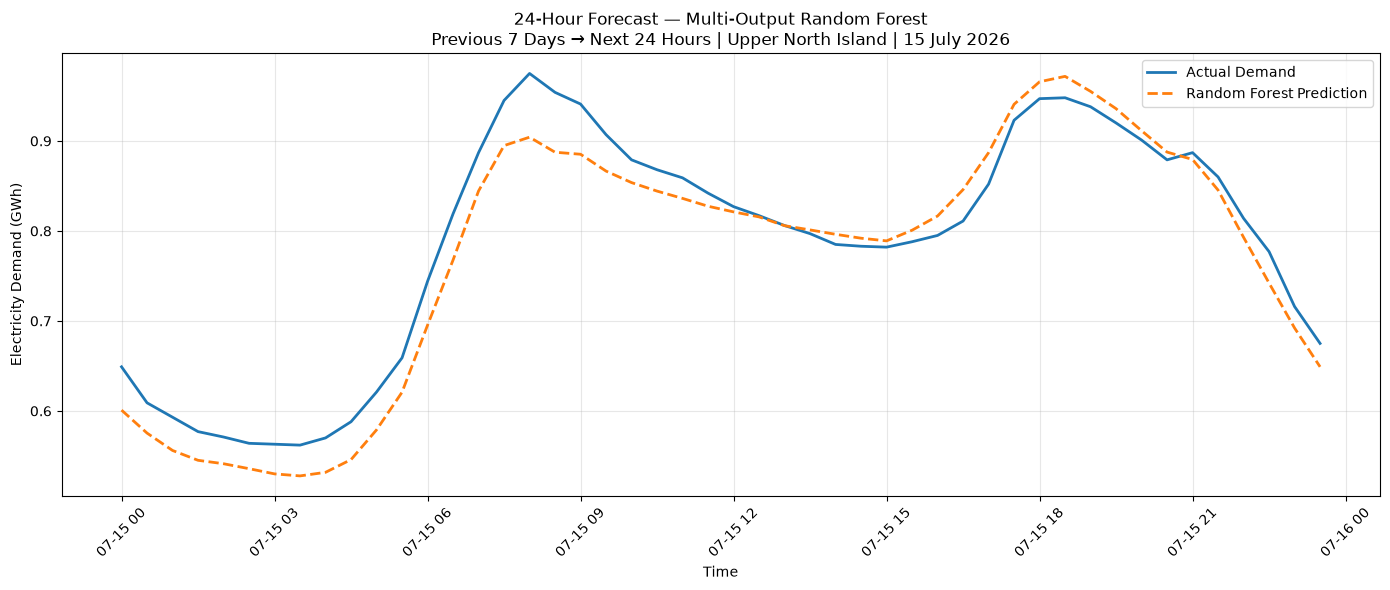

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

# Generate timestamps for the forecast day
timestamps = pd.date_range(
    start="2026-07-15",
    periods=48,
    freq="30min"
)

# Plot actual and predicted demand
plt.figure(figsize=(14, 6))

plt.plot(
    timestamps,
    actual_day,
    label="Actual Demand",
    linewidth=2
)

plt.plot(
    timestamps,
    predicted_day,
    label="Random Forest Prediction",
    linewidth=2,
    linestyle="--"
)

plt.title(
    "24-Hour Forecast — Multi-Output Random Forest\n"
    "Previous 7 Days → Next 24 Hours | Upper North Island | 15 July 2026"
)


plt.xlabel("Time")
plt.ylabel("Electricity Demand (GWh)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## 14. Extending Forecasting to Seven Days

We extend the multi-output Random Forest approach to
predict electricity demand for the next seven days.

The model will use:

- Input: Previous 14 days of demand (672 observations).
- Target: Following 7 days of demand (336 observations).

Unlike recursive forecasting, the model predicts the
entire seven-day period simultaneously.

We will evaluate its performance using MAE, RMSE and MAPE.

The objective is to determine whether historical demand
patterns can support accurate week-ahead forecasting.

In [16]:
# Seven-day forecasting configuration
lookback_days = 14
forecast_days = 7

X_weekly = []
y_weekly = []
weekly_target_dates = []

daily_values = daily_profiles.to_numpy()
dates = daily_profiles.index

for i in range(lookback_days, len(daily_profiles) - forecast_days + 1):

    # Historical input and future target dates
    window_dates = dates[
        i - lookback_days:i + forecast_days
    ]

    # Require consecutive calendar days
    expected_dates = pd.date_range(
        start=window_dates[0],
        periods=lookback_days + forecast_days,
        freq="D"
    )

    if not window_dates.equals(expected_dates):
        continue

    # Previous 14 days: 672 observations
    historical_demand = daily_values[
        i - lookback_days:i
    ].flatten()

    # Next 7 days: 336 observations
    future_demand = daily_values[
        i:i + forecast_days
    ].flatten()

    X_weekly.append(historical_demand)
    y_weekly.append(future_demand)
    weekly_target_dates.append(dates[i])

X_weekly = np.array(X_weekly)
y_weekly = np.array(y_weekly)

weekly_target_dates = pd.DatetimeIndex(
    weekly_target_dates
)

print("Training examples:", len(X_weekly))
print("Input shape:", X_weekly.shape)
print("Target shape:", y_weekly.shape)

print("\nFirst forecast date:", weekly_target_dates.min())
print("Last forecast date:", weekly_target_dates.max())

Training examples: 588
Input shape: (588, 672)
Target shape: (588, 336)

First forecast date: 2025-01-20 00:00:00
Last forecast date: 2026-10-25 00:00:00


## 15. Seven-Day Forecasting — Train-Test Split

We divide the seven-day forecasting dataset chronologically.

- Training period: January 2025 – June 2026
- Testing period: July 2026 – October 2026

Each example uses 14 days of historical electricity demand
to predict the following seven days.

To prevent data leakage, all seven target days in the
training set must occur before 1 July 2026.

This ensures the model is evaluated on unseen future data.

In [17]:
# Chronological split
split_date = pd.Timestamp("2026-07-01")

# Training forecasts must finish before July 2026
train_mask_weekly = (
    weekly_target_dates + pd.Timedelta(days=7)
    <= split_date
)

# Testing forecasts begin in July 2026
test_mask_weekly = weekly_target_dates >= split_date

# Split inputs
X_train_weekly = X_weekly[train_mask_weekly]
X_test_weekly = X_weekly[test_mask_weekly]

# Split targets
y_train_weekly = y_weekly[train_mask_weekly]
y_test_weekly = y_weekly[test_mask_weekly]

# Store dates
train_dates_weekly = weekly_target_dates[train_mask_weekly]
test_dates_weekly = weekly_target_dates[test_mask_weekly]

# Display results
print("Training examples:", len(X_train_weekly))
print("Testing examples:", len(X_test_weekly))

print("\nTraining input shape:", X_train_weekly.shape)
print("Training target shape:", y_train_weekly.shape)

print("\nTesting input shape:", X_test_weekly.shape)
print("Testing target shape:", y_test_weekly.shape)

print("\nLast training forecast starts:", train_dates_weekly.max())
print("First testing forecast starts:", test_dates_weekly.min())

Training examples: 493
Testing examples: 89

Training input shape: (493, 672)
Training target shape: (493, 336)

Testing input shape: (89, 672)
Testing target shape: (89, 336)

Last training forecast starts: 2026-06-24 00:00:00
First testing forecast starts: 2026-07-01 00:00:00


In [ ]:
## 16. Training the Seven-Day Multi-Output Random Forest

We train a Random Forest Regressor to predict seven days
of electricity demand simultaneously.

Model configuration:

- Algorithm: Random Forest Regressor
- Historical input: 14 days (672 half-hour observations)
- Forecast horizon: 7 days (336 half-hour predictions)
- Training examples: 493
- Testing examples: 89

Unlike recursive forecasting, this model generates all
336 predictions directly without feeding its previous
predictions back into the model.

The model is trained on historical observations before
July 2026 and evaluated on unseen future periods.

In [18]:
from sklearn.ensemble import RandomForestRegressor
import time

# Initialise seven-day Random Forest
rf_weekly = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Measure training time
start_time = time.time()

# Train the model
rf_weekly.fit(X_train_weekly, y_train_weekly)

training_time = time.time() - start_time

# Generate seven-day predictions
y_pred_weekly = rf_weekly.predict(X_test_weekly)

print("Seven-Day Random Forest training completed.")
print(f"Training time: {training_time:.2f} seconds")

print("\nPrediction shape:", y_pred_weekly.shape)

print("\nFirst forecast — first five predictions:")
print(y_pred_weekly[0][:5])

Seven-Day Random Forest training completed.
Training time: 10.23 seconds

Prediction shape: (89, 336)

First forecast — first five predictions:
[0.61866793 0.59184974 0.57239374 0.55960805 0.55700351]


## 17. Evaluating the Seven-Day Multi-Output Random Forest

We evaluate the seven-day Random Forest using unseen
electricity demand observations from July to October 2026.

The model uses 14 days of historical demand to predict
the following seven days simultaneously.

Performance is measured using:

- MAE: Mean Absolute Error
- RMSE: Root Mean Squared Error
- MAPE: Mean Absolute Percentage Error

We also calculate MAPE separately for each forecast day
to investigate whether accuracy decreases further into
the forecasting horizon.

Note: The 89 forecast windows overlap, meaning some
observations are evaluated more than once.

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Overall evaluation
mae_weekly = mean_absolute_error(
    y_test_weekly.ravel(),
    y_pred_weekly.ravel()
)

rmse_weekly = np.sqrt(
    mean_squared_error(
        y_test_weekly.ravel(),
        y_pred_weekly.ravel()
    )
)

mape_weekly = np.mean(
    np.abs(
        (y_test_weekly - y_pred_weekly) / y_test_weekly
    )
) * 100

print("Seven-Day Multi-Output Random Forest Results")
print("-" * 45)

print(f"MAE:  {mae_weekly:.5f} GWh")
print(f"RMSE: {rmse_weekly:.5f} GWh")
print(f"MAPE: {mape_weekly:.2f}%")

# Evaluate each forecast day separately
print("\nAccuracy by Forecast Day")
print("-" * 30)

for day in range(7):

    start = day * 48
    end = start + 48

    actual = y_test_weekly[:, start:end]
    predicted = y_pred_weekly[:, start:end]

    day_mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    print(f"Day {day + 1}: {day_mape:.2f}% MAPE")

Seven-Day Multi-Output Random Forest Results
---------------------------------------------
MAE:  0.03849 GWh
RMSE: 0.05249 GWh
MAPE: 4.99%

Accuracy by Forecast Day
------------------------------
Day 1: 4.47% MAPE
Day 2: 4.85% MAPE
Day 3: 5.06% MAPE
Day 4: 5.07% MAPE
Day 5: 5.17% MAPE
Day 6: 5.14% MAPE
Day 7: 5.18% MAPE


## 19. Seven-Day Forecasting — XGBoost

We train an XGBoost Regressor to predict seven days of
electricity demand using the previous 14 days.

Model configuration:

- Algorithm: XGBoost Regressor
- Input: 672 historical demand observations (14 days)
- Output: 336 predictions (7 days)
- Training examples: 493
- Testing examples: 89

We use the same chronological train-test split as our
Random Forest to ensure a fair comparison.

Our objective is to determine whether gradient boosting
improves seven-day electricity demand forecasting accuracy.

Random Forest benchmark: 4.99% MAPE.

In [20]:
import xgboost as xgb
import time

# Initialise XGBoost
xgb_weekly = xgb.XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    multi_strategy="multi_output_tree",
    random_state=42,
    n_jobs=-1
)

# Measure training time
start_time = time.time()

# Train model
xgb_weekly.fit(X_train_weekly, y_train_weekly)

training_time = time.time() - start_time

# Generate predictions
y_pred_xgb_weekly = xgb_weekly.predict(X_test_weekly)

print("Seven-Day XGBoost training completed.")
print(f"Training time: {training_time:.2f} seconds")

print("\nPrediction shape:", y_pred_xgb_weekly.shape)

print("\nFirst forecast — first five predictions:")
print(y_pred_xgb_weekly[0][:5])

Seven-Day XGBoost training completed.
Training time: 3407.41 seconds

Prediction shape: (89, 336)

First forecast — first five predictions:
[0.63559204 0.6074153  0.58743095 0.5733934  0.57085717]


## 20. Comparing XGBoost and Random Forest

We evaluate the seven-day XGBoost model against our
previous Multi-Output Random Forest.

Both models use:

- 14 days of historical electricity demand (672 inputs).
- Seven-day forecasting horizon (336 outputs).
- Identical training and testing datasets.
- 89 test forecast windows.

We compare MAE, RMSE, MAPE and training time.

Random Forest benchmark: 4.99% MAPE.

In [21]:
# Calculate XGBoost performance
xgb_mae = mean_absolute_error(
    y_test_weekly.ravel(),
    y_pred_xgb_weekly.ravel()
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test_weekly.ravel(),
        y_pred_xgb_weekly.ravel()
    )
)

xgb_mape = np.mean(
    np.abs(
        (y_test_weekly - y_pred_xgb_weekly) / y_test_weekly
    )
) * 100

# Compare both models
print("Seven-Day Forecasting — Model Comparison")
print("-" * 55)

print(f"{'Metric':<18} {'Random Forest':<18} {'XGBoost'}")
print("-" * 55)

print(f"{'MAE (GWh)':<18} {mae_weekly:<18.5f} {xgb_mae:.5f}")
print(f"{'RMSE (GWh)':<18} {rmse_weekly:<18.5f} {xgb_rmse:.5f}")
print(f"{'MAPE (%)':<18} {mape_weekly:<18.2f} {xgb_mape:.2f}")
print(f"{'Training (sec)':<18} {10.23:<18.2f} {training_time:.2f}")

print("\nBest model by MAPE:")
print("XGBoost" if xgb_mape < mape_weekly else "Random Forest")

Seven-Day Forecasting — Model Comparison
-------------------------------------------------------
Metric             Random Forest      XGBoost
-------------------------------------------------------
MAE (GWh)          0.03849            0.03880
RMSE (GWh)         0.05249            0.05297
MAPE (%)           4.99               5.02
Training (sec)     10.23              3407.41

Best model by MAPE:
Random Forest


In [22]:
import joblib
from pathlib import Path

# Models directory
models_dir = Path.cwd().parent / "models"
models_dir.mkdir(exist_ok=True)

# Save trained models
joblib.dump(
    rf_daily,
    models_dir / "random_forest_24h.pkl"
)

joblib.dump(
    rf_weekly,
    models_dir / "random_forest_7day.pkl"
)

# Save XGBoost separately
xgb_weekly.save_model(
    str(models_dir / "xgboost_7day.json")
)

print("All forecasting models saved successfully.")

All forecasting models saved successfully.


## 21. Seven-Day Seasonal Naïve Baseline

We establish a baseline using electricity demand from
the previous week.

For each seven-day forecast, we predict that demand
will repeat the pattern observed during the previous
seven days.

This provides a benchmark for evaluating whether
Random Forest learns useful relationships beyond
historical weekly seasonality.

Both models are evaluated on identical test observations.

In [23]:
# Previous week's demand is the final 336 input values
baseline_weekly = X_test_weekly[:, -336:]

# Calculate baseline performance
baseline_mae = mean_absolute_error(
    y_test_weekly.ravel(),
    baseline_weekly.ravel()
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test_weekly.ravel(),
        baseline_weekly.ravel()
    )
)

baseline_mape = np.mean(
    np.abs(
        (y_test_weekly - baseline_weekly) / y_test_weekly
    )
) * 100

print("Seven-Day Forecasting Comparison")
print("-" * 45)

print(f"{'Model':<25} {'MAPE':>10}")
print("-" * 45)

print(f"{'Seasonal Naive':<25} {baseline_mape:>9.2f}%")
print(f"{'Random Forest':<25} {mape_weekly:>9.2f}%")
print(f"{'XGBoost':<25} {xgb_mape:>9.2f}%")

print("\nBaseline MAE:", round(baseline_mae, 5))
print("Baseline RMSE:", round(baseline_rmse, 5))

Seven-Day Forecasting Comparison
---------------------------------------------
Model                           MAPE
---------------------------------------------
Seasonal Naive                 6.26%
Random Forest                  4.99%
XGBoost                        5.02%

Baseline MAE: 0.04744
Baseline RMSE: 0.06487


22. Seven-Day Forecasting — Baseline Evaluation

Objective

To determine whether machine-learning models provide measurable improvements over a simple seasonal forecasting approach.

Model Performance

Model	MAE (GWh)	RMSE (GWh)	MAPE
Seasonal Naïve	0.04744	0.06487	6.26%
Random Forest	0.03849	0.05249	4.99%
XGBoost	0.03880	0.05297	5.02%

Key Findings

The multi-output Random Forest achieved the lowest prediction error across all three evaluation metrics.

Compared with the seasonal naïve baseline, Random Forest achieved:

* An 18.9% reduction in MAE.
* A 19.1% reduction in RMSE.
* A 20.3% reduction in MAPE.

XGBoost also outperformed the baseline but did not improve upon Random Forest.

Interpretation

The seasonal naïve model assumes that electricity demand during the coming week will follow the same pattern as the previous week.

Random Forest improves upon this approach by learning relationships from 14 days of historical electricity demand.

The results suggest that historical demand contains predictive information beyond simple weekly repetition.

Conclusion

Random Forest is the preferred model for seven-day electricity demand forecasting in the Upper North Island.

It achieved 4.99% MAPE across 89 overlapping test forecast windows while requiring substantially less training time than XGBoost.

Further evaluation across additional time periods and regions would help establish the model’s generalisability.